[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/05-deep-learning/notebooks/02-mlp-on-digits.ipynb)

# 05-02 · Your first neural network: an MLP on handwritten digits

**Goal:** build, train and evaluate a **multi-layer perceptron (MLP)** — a stack of fully connected layers — on 8×8 handwritten digits. Along the way we write the full training loop, plot **loss curves**, and **save and load** the trained weights.

Takes well under a minute on a laptop CPU. Works unchanged on a Colab GPU.

## Setup: device and reproducibility

- `device` is `"cuda"` if a GPU is available (e.g. Colab with a T4 GPU), otherwise `"cpu"`. All later code uses this variable, so the same notebook runs anywhere.
- `torch.manual_seed(0)` fixes the random starting weights so you get the same results each run.
- On CPU we use one thread: these models are tiny, and many threads fighting over tiny jobs is slower (especially on shared or busy machines).

In [1]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    torch.set_num_threads(1)
torch.manual_seed(0)
print("PyTorch", torch.__version__, "| running on:", device)

PyTorch 2.15.0+cpu | running on: cpu


## Load the digits and make tensors

`load_digits` ships inside scikit-learn: 1,797 greyscale images of handwritten digits, each 8×8 pixels with values 0–16.

1. Divide by 16 so pixels are between 0 and 1 (neural networks train best on small, similar-sized inputs).
2. Split into **train** (60%), **validation** (20%, for watching overfitting) and **test** (20%, locked away until the end).
3. Convert to tensors: inputs as `float32`, labels as `long` (whole numbers), which `CrossEntropyLoss` requires.

In [2]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = digits.data.astype("float32") / 16.0          # shape (1797, 64), values 0..1
y = digits.target                                 # shape (1797,), values 0..9

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25,
                                                  random_state=0, stratify=y_trainval)

X_train_t, X_val_t, X_test_t = (torch.tensor(a) for a in (X_train, X_val, X_test))
y_train_t, y_val_t, y_test_t = (torch.tensor(a, dtype=torch.long) for a in (y_train, y_val, y_test))
print("train", tuple(X_train_t.shape), "val", tuple(X_val_t.shape), "test", tuple(X_test_t.shape))

train (1077, 64) val (360, 64) test (360, 64)


## Look at some digits

Each row of `X` is 64 numbers; reshaped to 8×8 it is a tiny picture. These are low-resolution — even humans find some hard.

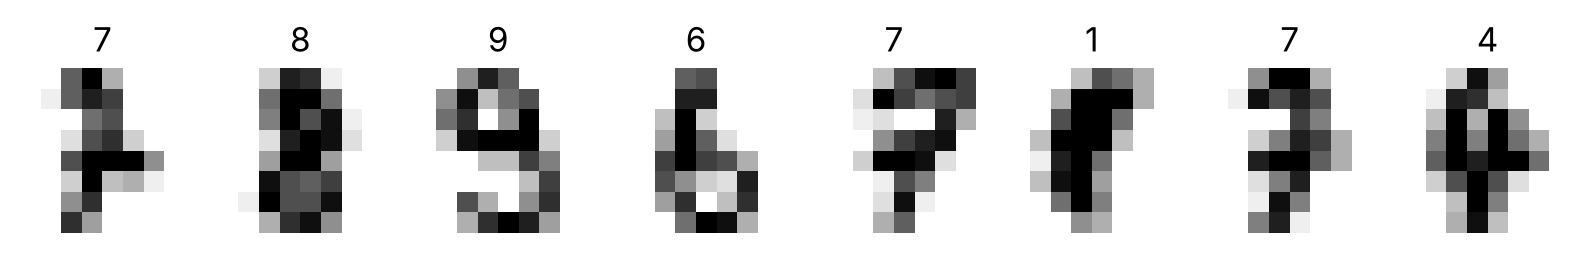

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 8, figsize=(10, 1.8))
for ax, img, label in zip(axes, X_train[:8], y_train[:8]):
    ax.imshow(img.reshape(8, 8), cmap="gray_r"); ax.set_title(str(label)); ax.axis("off")
plt.show()

## Batches with DataLoader

A `TensorDataset` pairs each input with its label. A `DataLoader` serves them in **batches** (groups of 64 here) and shuffles the order every **epoch** (full pass over the data). Shuffling stops the network from learning anything about the order of examples.

In [4]:
from torch.utils.data import TensorDataset, DataLoader
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)
xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(train_loader))

one batch: (64, 64) (64,) | batches per epoch: 17


## Define the model with nn.Module

- `__init__` creates the layers (where the weights live).
- `forward` says how data flows: 64 pixels → 128 hidden neurons → ReLU → 10 **logits** (raw scores, one per digit).

No softmax at the end: `CrossEntropyLoss` applies it internally.

In [5]:
import torch.nn as nn

class DigitMLP(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.layer1 = nn.Linear(64, hidden)
        self.layer2 = nn.Linear(hidden, 10)

    def forward(self, x):
        x = torch.relu(self.layer1(x))
        return self.layer2(x)

model = DigitMLP().to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print("trainable parameters:", n_params, " (= 64*128 + 128 + 128*10 + 10)")

DigitMLP(
  (layer1): Linear(in_features=64, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=10, bias=True)
)
trainable parameters: 9610  (= 64*128 + 128 + 128*10 + 10)


Before training, the weights are random, so predictions are random guesses (about 10% accuracy). Let us confirm, and look at what the untrained model outputs for one image.

In [6]:
with torch.no_grad():
    logits = model(X_val_t[:1].to(device))
print("logits:", logits.cpu().numpy().round(2))
print("softmax probabilities:", torch.softmax(logits, dim=1).cpu().numpy().round(2))

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        preds = model(X.to(device)).argmax(dim=1)
    return (preds == y.to(device)).float().mean().item()

print("untrained validation accuracy:", round(accuracy(model, X_val_t, y_val_t), 3))

logits: [[-0.    0.25  0.02  0.09  0.01 -0.05 -0.1  -0.28  0.06  0.14]]
softmax probabilities: [[0.1  0.13 0.1  0.11 0.1  0.09 0.09 0.07 0.1  0.11]]
untrained validation accuracy: 0.097


## The training loop, line by line

Read every comment. This exact structure trains every PyTorch model, up to and including LLMs.

Each epoch we also compute the **validation loss** in `eval()` mode under `torch.no_grad()` (no gradient bookkeeping, so it is faster and uses less memory). We keep a history to plot.

In [7]:
loss_fn = nn.CrossEntropyLoss()                               # classification loss (takes logits)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)     # Adam: a good default optimizer
history = {"train_loss": [], "val_loss": [], "val_acc": []}

for epoch in range(40):                                       # 40 passes over the training data
    model.train()                                             # training mode
    running = 0.0
    for xb, yb in train_loader:                               # one batch at a time
        xb, yb = xb.to(device), yb.to(device)                 # same device as the model
        logits = model(xb)                                    # 1. forward pass
        loss = loss_fn(logits, yb)                            # 2. how wrong?
        optimizer.zero_grad()                                 # 3. clear old gradients
        loss.backward()                                       # 4. backprop
        optimizer.step()                                      # 5. update weights
        running += loss.item() * len(xb)                      # add up loss for the epoch average
    history["train_loss"].append(running / len(X_train_t))

    model.eval()                                              # evaluation mode
    with torch.no_grad():                                     # no gradients needed
        val_logits = model(X_val_t.to(device))
        history["val_loss"].append(loss_fn(val_logits, y_val_t.to(device)).item())
        history["val_acc"].append((val_logits.argmax(1) == y_val_t.to(device)).float().mean().item())
    if epoch % 5 == 0 or epoch == 39:
        print(f"epoch {epoch:2d}  train_loss={history['train_loss'][-1]:.3f}  "
              f"val_loss={history['val_loss'][-1]:.3f}  val_acc={history['val_acc'][-1]:.3f}")

epoch  0  train_loss=2.199  val_loss=2.086  val_acc=0.728
epoch  5  train_loss=0.851  val_loss=0.771  val_acc=0.900
epoch 10  train_loss=0.367  val_loss=0.369  val_acc=0.942


epoch 15  train_loss=0.228  val_loss=0.246  val_acc=0.944
epoch 20  train_loss=0.168  val_loss=0.193  val_acc=0.956
epoch 25  train_loss=0.128  val_loss=0.167  val_acc=0.961


epoch 30  train_loss=0.105  val_loss=0.151  val_acc=0.972
epoch 35  train_loss=0.089  val_loss=0.139  val_acc=0.969
epoch 39  train_loss=0.080  val_loss=0.134  val_acc=0.969


## Plot the loss curves

Both losses should fall and then level off. If validation loss started rising while training loss kept falling, that would be **overfitting** (notebook 04 deals with it).

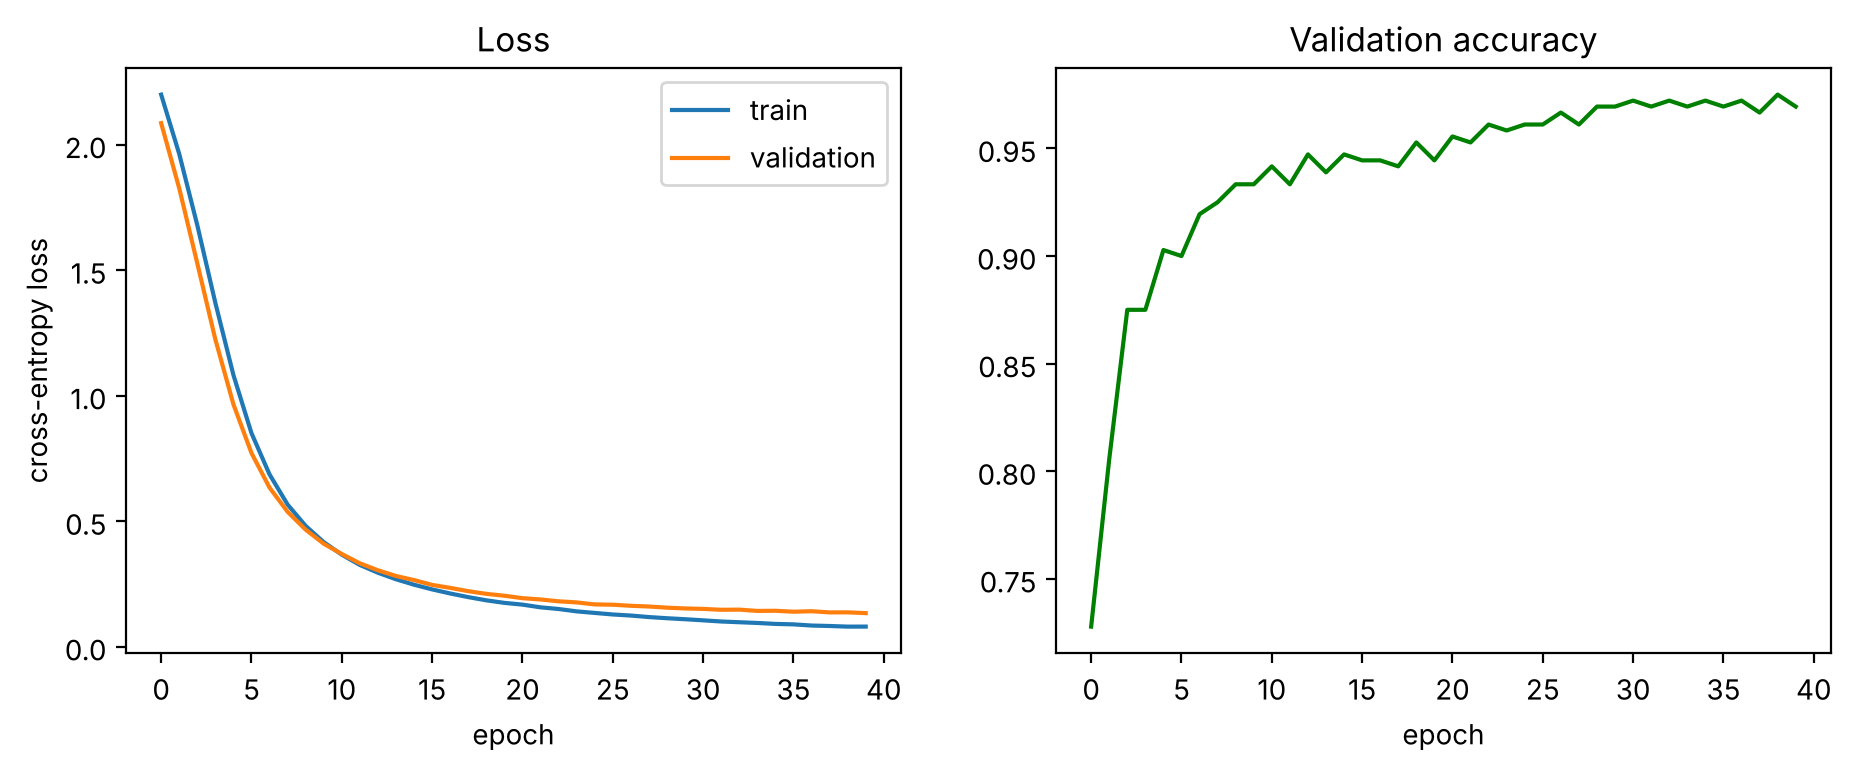

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(history["train_loss"], label="train"); axes[0].plot(history["val_loss"], label="validation")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss"); axes[0].legend(); axes[0].set_title("Loss")
axes[1].plot(history["val_acc"], color="green"); axes[1].set_xlabel("epoch"); axes[1].set_title("Validation accuracy")
plt.show()

## Final test — once

Only now do we use the locked-away test set. We also print a **confusion matrix** (from module 04): rows are true digits, columns predicted digits, the diagonal holds the correct answers.

In [9]:
from sklearn.metrics import confusion_matrix
print("test accuracy:", round(accuracy(model, X_test_t, y_test_t), 3))
model.eval()
with torch.no_grad():
    test_preds = model(X_test_t.to(device)).argmax(1).cpu().numpy()
print(confusion_matrix(y_test, test_preds))

test accuracy: 0.956
[[35  0  0  0  1  0  0  0  0  0]
 [ 0 35  0  0  0  0  0  0  1  0]
 [ 0  1 34  0  0  0  0  0  0  0]
 [ 0  0  0 35  0  0  0  1  1  0]
 [ 0  1  0  0 34  0  0  0  1  0]
 [ 0  0  0  1  0 36  0  0  0  0]
 [ 0  1  0  0  0  1 34  0  0  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  3  0  0  0  1  0  0 31  0]
 [ 0  1  0  0  0  1  0  0  0 34]]


Let us look at some mistakes. Often they are digits a human would also hesitate over.

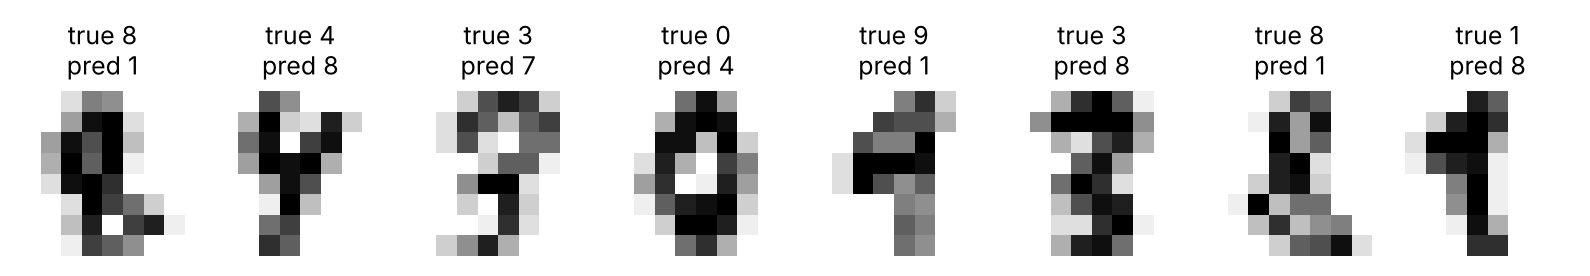

In [10]:
wrong = np.where(test_preds != y_test)[0][:8]
fig, axes = plt.subplots(1, max(len(wrong), 1), figsize=(10, 1.9))
axes = np.atleast_1d(axes)
for ax, i in zip(axes, wrong):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r"); ax.axis("off")
    ax.set_title(f"true {y_test[i]}\npred {test_preds[i]}", fontsize=9)
plt.show()

## Save and load the weights

`model.state_dict()` is a dictionary of all learned weights. We save it with `torch.save`, then build a **fresh** model from the class and load the weights into it. `map_location="cpu"` makes GPU-trained weights load on any machine.

We save into a temporary folder so the course repository stays clean; in your own project choose a real path like `models/digit_mlp.pt`.

In [11]:
import os, tempfile
print("weights stored:", {k: tuple(v.shape) for k, v in model.state_dict().items()})

path = os.path.join(tempfile.gettempdir(), "digit_mlp.pt")
torch.save(model.state_dict(), path)
print("saved", path, round(os.path.getsize(path) / 1024, 1), "KB")

fresh = DigitMLP().to(device)                                  # random weights
print("fresh model accuracy:", round(accuracy(fresh, X_test_t, y_test_t), 3))
fresh.load_state_dict(torch.load(path, map_location=device))   # trained weights
print("after loading:      ", round(accuracy(fresh, X_test_t, y_test_t), 3))

weights stored: {'layer1.weight': (128, 64), 'layer1.bias': (128,), 'layer2.weight': (10, 128), 'layer2.bias': (10,)}
saved /tmp/digit_mlp.pt 39.9 KB
fresh model accuracy: 0.097
after loading:       0.956


## Recap

- `nn.Module` with `__init__` (layers) and `forward` (data flow).
- `DataLoader` gives shuffled batches.
- Loop: forward → loss → `zero_grad` → `backward` → `step`; validate with `eval()` + `no_grad()`.
- Plot train vs validation loss every time you train.
- `torch.save(model.state_dict())` / `load_state_dict(torch.load(...))`.

**Try it:** change `hidden=128` to `hidden=16` and to `hidden=512`. How do accuracy and parameter count change? Try `lr=1e-1` and `lr=1e-5`.